# Notebook 2 — Calibration & Selective Prediction

**Student** Xin Yiing · **Group** CrisisLens (36118)

**Member 3 scope:** temperature scaling, ECE measurement, reliability diagrams, coverage-risk curve, and review threshold selection.

**This notebook** loads the winning model's logits from Notebook 1, fits temperature scaling on validation, evaluates calibration before and after scaling, constructs a coverage-risk curve, selects an operating threshold, and produces the final prediction CSVs with `needs_review` flags. All calibration parameters are frozen on validation and applied unchanged to test.

## 1 — Environment Setup

### 1.1 — Install dependencies

In [1]:
# One-time environment setup for Kaggle or fresh venv.
# Uncomment the lines below as needed.

# !pip install -q scikit-learn matplotlib seaborn

### 1.2 — Imports

In [2]:
# Standard library
import os, json, warnings
from pathlib import Path

# Numeric and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Optimisation
from scipy.optimize import minimize_scalar

# Evaluation
from sklearn.metrics import f1_score

# ── Display and warnings ──
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

### 1.3 — Labels and constants

In [3]:
LABELS = [
    "caution_and_advice",
    "displaced_people_and_evacuations",
    "infrastructure_and_utility_damage",
    "injured_or_dead_people",
    "missing_or_found_people",
    "not_humanitarian",
    "other_relevant_information",
    "requests_or_urgent_needs",
    "rescue_volunteering_or_donation_effort",
    "sympathy_and_support",
]
NUM_LABELS = len(LABELS)
LABEL2ID   = {l: i for i, l in enumerate(LABELS)}
ID2LABEL   = {i: l for i, l in enumerate(LABELS)}

ECE_BINS = 15

print(f"{'Labels':<20} {NUM_LABELS}")
print(f"{'ECE bins':<20} {ECE_BINS}")

Labels               10
ECE bins             15


### 1.4 — Resolve paths

In [4]:
import sys

# Detect environment: Kaggle has /kaggle/working directory
ON_KAGGLE = os.path.exists("/kaggle/working") and sys.platform != "win32"
BASE      = "/kaggle/working" if ON_KAGGLE else "."

# For local Windows/non-Kaggle runs, use humaid-nb1-outputs
if not ON_KAGGLE:
    OUTPUT_DIR = os.path.abspath(os.path.join(BASE, "humaid-nb1-outputs"))
else:
    OUTPUT_DIR = os.path.join(BASE, "outputs")

RESULTS_DIR = os.path.join(OUTPUT_DIR, "results", "transformer")
PRED_DIR    = os.path.join(OUTPUT_DIR, "predictions", "transformer")
LOGITS_DIR  = os.path.join(OUTPUT_DIR, "logits", "transformer")

for d in [RESULTS_DIR, PRED_DIR]:
    os.makedirs(d, exist_ok=True)

# Load winner config from Notebook 1
config_path = os.path.join(RESULTS_DIR, "go_no_go_decision.json")
assert os.path.exists(config_path), f"Run Notebook 1 first. Missing: {config_path}"

with open(config_path) as f:
    winner_config = json.load(f)

WINNER_RID = winner_config["winner_run_id"]

print(f"{'Kaggle':<20} {ON_KAGGLE}")
print(f"{'BASE':<20} {BASE}")
print(f"{'OUTPUT_DIR':<20} {OUTPUT_DIR}")
print(f"{'Winner run':<20} {WINNER_RID}")
print(f"{'Encoder':<20} {winner_config['encoder']}")
print(f"{'Imbalance':<20} {winner_config['imbalance']}")

Kaggle               False
BASE                 .
OUTPUT_DIR           C:\Users\looxi\OneDrive\Desktop\ANLP - Arnick\Assignment 2 brief\member 3\humaid-nb1-outputs
Winner run           A4
Encoder              cardiffnlp/twitter-roberta-base
Imbalance            plain


## 2 — Load Logits

### 2.1 — Load validation and test logits from Notebook 1

In [5]:
# PART 2 step 1 — load saved logits and labels
val_logits  = np.load(os.path.join(LOGITS_DIR, f"{WINNER_RID}_val_logits.npy"))
val_labels  = np.load(os.path.join(LOGITS_DIR, f"{WINNER_RID}_val_labels.npy"))
test_logits = np.load(os.path.join(LOGITS_DIR, f"{WINNER_RID}_test_logits.npy"))
test_labels = np.load(os.path.join(LOGITS_DIR, f"{WINNER_RID}_test_labels.npy"))

print(f"{'Val logits':<20} {val_logits.shape}")
print(f"{'Val labels':<20} {val_labels.shape}")
print(f"{'Test logits':<20} {test_logits.shape}")
print(f"{'Test labels':<20} {test_labels.shape}")

Val logits           (7793, 10)
Val labels           (7793,)
Test logits          (15160, 10)
Test labels          (15160,)


## 3 — Temperature Scaling

### 3.1 — Softmax and NLL helpers

In [6]:
# softmax_with_temperature — apply temperature scaling to logits
def softmax_with_temperature(logits, T):
    scaled = logits / T
    exp = np.exp(scaled - scaled.max(axis=1, keepdims=True))
    return exp / exp.sum(axis=1, keepdims=True)


# nll — negative log-likelihood for temperature fitting
def nll(T, logits, labels):
    probs = softmax_with_temperature(logits, T)
    log_probs = np.log(probs[np.arange(len(labels)), labels] + 1e-12)
    return -log_probs.mean()


print("softmax_with_temperature, nll defined")

softmax_with_temperature, nll defined


### 3.2 — Fit temperature on validation

In [7]:
# PART 3 step 2 — minimise NLL on validation to find optimal T
result = minimize_scalar(nll, bounds=(0.1, 10.0), args=(val_logits, val_labels), method="bounded")
T_opt  = result.x

nll_before = nll(1.0, val_logits, val_labels)
nll_after  = nll(T_opt, val_logits, val_labels)

print(f"{'T (fitted)':<20} {T_opt:.4f}")
print(f"{'NLL before (T=1)':<20} {nll_before:.4f}")
print(f"{'NLL after':<20} {nll_after:.4f}")

T (fitted)           1.3509
NLL before (T=1)     0.6586
NLL after            0.6123


**3.2 Explanation**

- Temperature T > 1 softens the probability distribution, reducing overconfidence.
- T < 1 sharpens it. The fitted value reflects how overconfident the model is.
- T is fitted on validation only and frozen for all downstream use.

## 4 — ECE and Reliability Diagrams

### 4.1 — ECE computation

In [8]:
# compute_ece — expected calibration error with equal-width bins
def compute_ece(probs, labels, n_bins=15):
    confidences = probs.max(axis=1)
    predictions = probs.argmax(axis=1)
    correct     = (predictions == labels).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_data = []

    for i in range(n_bins):
        mask = (confidences > bin_edges[i]) & (confidences <= bin_edges[i + 1])
        if mask.sum() == 0:
            bin_data.append({"bin_lower": bin_edges[i], "bin_upper": bin_edges[i+1],
                             "count": 0, "avg_confidence": 0, "avg_accuracy": 0})
            continue
        avg_conf = confidences[mask].mean()
        avg_acc  = correct[mask].mean()
        count    = int(mask.sum())
        ece += (count / len(labels)) * abs(avg_acc - avg_conf)
        bin_data.append({"bin_lower": bin_edges[i], "bin_upper": bin_edges[i+1],
                         "count": count, "avg_confidence": float(avg_conf),
                         "avg_accuracy": float(avg_acc)})

    return float(ece), bin_data


print("compute_ece defined")

compute_ece defined


### 4.2 — ECE before and after temperature scaling

In [9]:
# PART 4 step 2 — compute ECE on val and test, before and after scaling
val_probs_pre   = softmax_with_temperature(val_logits, 1.0)
val_probs_post  = softmax_with_temperature(val_logits, T_opt)
test_probs_pre  = softmax_with_temperature(test_logits, 1.0)
test_probs_post = softmax_with_temperature(test_logits, T_opt)

val_ece_pre,  val_bins_pre  = compute_ece(val_probs_pre,  val_labels, ECE_BINS)
val_ece_post, val_bins_post = compute_ece(val_probs_post, val_labels, ECE_BINS)
test_ece_pre,  test_bins_pre  = compute_ece(test_probs_pre,  test_labels, ECE_BINS)
test_ece_post, test_bins_post = compute_ece(test_probs_post, test_labels, ECE_BINS)

print(f"{'Split':<15} {'ECE (T=1)':<15} {'ECE (T=opt)':<15}")
print("-" * 45)
print(f"{'Validation':<15} {val_ece_pre:<15.4f} {val_ece_post:<15.4f}")
print(f"{'Test':<15} {test_ece_pre:<15.4f} {test_ece_post:<15.4f}")

ece_table = {
    "temperature": round(T_opt, 4),
    "validation": {"ece_before": round(val_ece_pre, 4), "ece_after": round(val_ece_post, 4)},
    "test":       {"ece_before": round(test_ece_pre, 4), "ece_after": round(test_ece_post, 4)},
}
with open(os.path.join(RESULTS_DIR, "ece_table.json"), "w") as f:
    json.dump(ece_table, f, indent=2)
print(f"\n{'Saved':<20} ece_table.json")

Split           ECE (T=1)       ECE (T=opt)    
---------------------------------------------
Validation      0.0960          0.0369         
Test            0.0931          0.0351         

Saved                ece_table.json


**4.2 Explanation**

- ECE measures the gap between predicted confidence and actual accuracy across bins.
- A well-calibrated model has ECE close to 0.
- Temperature scaling should reduce ECE on both validation (where T was fitted) and test (unseen).

### 4.3 — Reliability diagrams

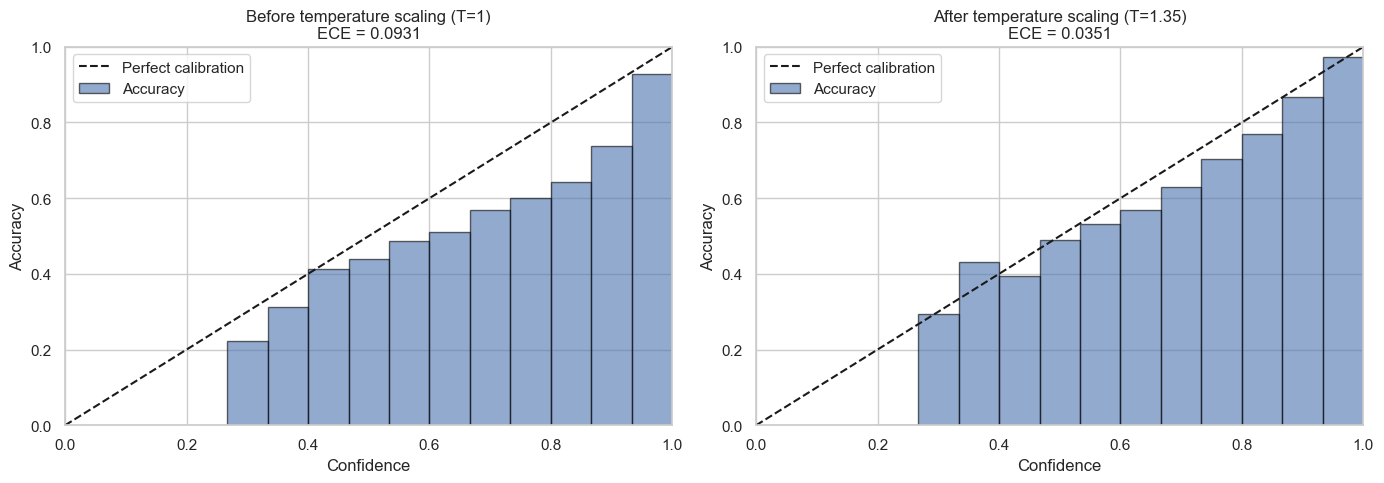

Saved                calibration_pre.png (contains both panels)


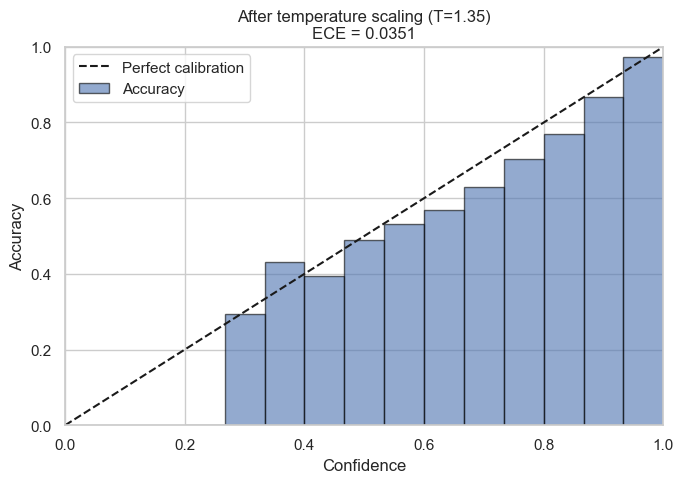

Saved                calibration_post.png


In [10]:
# PART 4 step 3 — plot reliability diagrams before and after scaling


# plot_reliability — single reliability diagram
def plot_reliability(bin_data, ece, title, ax):
    confs = [b["avg_confidence"] for b in bin_data if b["count"] > 0]
    accs  = [b["avg_accuracy"]  for b in bin_data if b["count"] > 0]
    counts = [b["count"] for b in bin_data if b["count"] > 0]
    midpoints = [(b["bin_lower"] + b["bin_upper"]) / 2 for b in bin_data if b["count"] > 0]

    ax.bar(midpoints, accs, width=1.0/ECE_BINS, alpha=0.6, edgecolor="black", label="Accuracy")
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Confidence")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"{title}\nECE = {ece:.4f}")
    ax.legend(loc="upper left")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_reliability(test_bins_pre,  test_ece_pre,  "Before temperature scaling (T=1)", axes[0])
plot_reliability(test_bins_post, test_ece_post, f"After temperature scaling (T={T_opt:.2f})", axes[1])
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "calibration_pre.png"), dpi=180, bbox_inches="tight")
plt.show()
print(f"{'Saved':<20} calibration_pre.png (contains both panels)")

# Also save the post-only version
fig2, ax2 = plt.subplots(figsize=(7, 5))
plot_reliability(test_bins_post, test_ece_post, f"After temperature scaling (T={T_opt:.2f})", ax2)
plt.tight_layout()
fig2.savefig(os.path.join(RESULTS_DIR, "calibration_post.png"), dpi=180, bbox_inches="tight")
plt.show()
print(f"{'Saved':<20} calibration_post.png")

## 5 — Selective Prediction

### 5.1 — Coverage-risk curve computation

In [11]:
# PART 5 step 1 — sweep tau from 0 to 1 and compute coverage and risk


# coverage_risk_curve — compute coverage and risk at each threshold
def coverage_risk_curve(confidences, correct_mask, n_points=200):
    taus     = np.linspace(0, 1, n_points)
    coverage = []
    risk     = []

    for tau in taus:
        accepted = confidences >= tau
        cov = accepted.mean()
        if cov == 0:
            err = 0.0
        else:
            err = 1.0 - correct_mask[accepted].mean()
        coverage.append(float(cov))
        risk.append(float(err))

    return {
        "tau":      taus.tolist(),
        "coverage": coverage,
        "risk":     risk,
    }


# Use calibrated (post-scaling) confidences on validation
val_confidences = val_probs_post.max(axis=1)
val_preds       = val_probs_post.argmax(axis=1)
val_correct     = (val_preds == val_labels)

curve_data = coverage_risk_curve(val_confidences, val_correct)

print(f"{'Tau points':<20} {len(curve_data['tau'])}")
print(f"{'Coverage range':<20} [{min(curve_data['coverage']):.2f}, {max(curve_data['coverage']):.2f}]")
print(f"{'Risk range':<20} [{min(curve_data['risk']):.4f}, {max(curve_data['risk']):.4f}]")

Tau points           200
Coverage range       [0.00, 1.00]
Risk range           [0.0000, 0.2223]


### 5.2 — Select operating threshold

In [12]:
# PART 5 step 2 — choose tau that gives risk <= 5% with maximum coverage


# select_threshold — find tau for target risk with highest coverage
def select_threshold(curve_data, target_risk=0.05):
    best_tau = 1.0
    best_cov = 0.0
    for tau, cov, r in zip(curve_data["tau"], curve_data["coverage"], curve_data["risk"]):
        if r <= target_risk and cov > best_cov:
            best_tau = tau
            best_cov = cov
    return best_tau, best_cov


TARGET_RISK = 0.05
tau_selected, cov_at_tau = select_threshold(curve_data, TARGET_RISK)

# Also compute risk at selected tau on validation
accepted_mask = val_confidences >= tau_selected
risk_at_tau   = 1.0 - val_correct[accepted_mask].mean() if accepted_mask.any() else 0.0
review_rate   = 1.0 - cov_at_tau

print(f"{'Target risk':<25} {TARGET_RISK:.2%}")
print(f"{'Selected tau':<25} {tau_selected:.4f}")
print(f"{'Coverage at tau':<25} {cov_at_tau:.2%}")
print(f"{'Risk at tau (val)':<25} {risk_at_tau:.4f}")
print(f"{'Review rate':<25} {review_rate:.2%}")

Target risk               5.00%
Selected tau              0.8945
Coverage at tau           44.89%
Risk at tau (val)         0.0466
Review rate               55.11%


**5.2 Explanation**

- The threshold tau is the minimum calibrated confidence for auto-acceptance.
- Samples below tau are flagged `needs_review=True` and routed to human review.
- The target risk (5% error rate among auto-accepted samples) is a practical choice. A stricter target increases the review queue; a looser target lets more errors through.
- Tau is frozen here and applied unchanged to test and unseen events.

### 5.3 — Coverage-risk curve plot

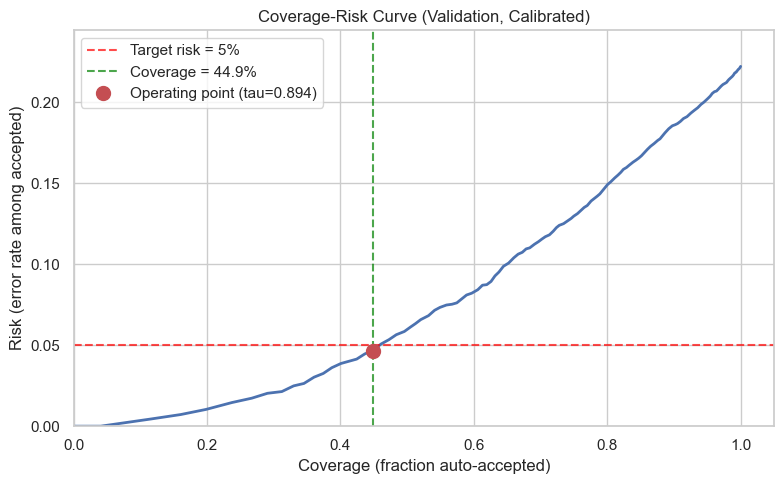

Saved                coverage_risk_curve.png
Saved                coverage_risk_data.json


In [13]:
# PART 5 step 3 — plot the coverage-risk curve with operating point
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(curve_data["coverage"], curve_data["risk"], "b-", linewidth=2)
ax.axhline(y=TARGET_RISK, color="red", linestyle="--", alpha=0.7, label=f"Target risk = {TARGET_RISK:.0%}")
ax.axvline(x=cov_at_tau, color="green", linestyle="--", alpha=0.7, label=f"Coverage = {cov_at_tau:.1%}")
ax.plot(cov_at_tau, risk_at_tau, "ro", markersize=10, label=f"Operating point (tau={tau_selected:.3f})")
ax.set_xlabel("Coverage (fraction auto-accepted)")
ax.set_ylabel("Risk (error rate among accepted)")
ax.set_title("Coverage-Risk Curve (Validation, Calibrated)")
ax.legend()
ax.set_xlim(0, 1.05)
ax.set_ylim(0, max(curve_data["risk"]) * 1.1)
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "coverage_risk_curve.png"), dpi=180, bbox_inches="tight")
plt.show()
print(f"{'Saved':<20} coverage_risk_curve.png")

# Save curve data
with open(os.path.join(RESULTS_DIR, "coverage_risk_data.json"), "w") as f:
    json.dump(curve_data, f)
print(f"{'Saved':<20} coverage_risk_data.json")

## 6 — Apply to Test Set

### 6.1 — Test set coverage and risk at frozen tau

In [14]:
# PART 6 step 1 — apply frozen tau to test set
test_confidences = test_probs_post.max(axis=1)
test_preds_arr   = test_probs_post.argmax(axis=1)
test_correct     = (test_preds_arr == test_labels)

test_accepted    = test_confidences >= tau_selected
test_coverage    = test_accepted.mean()
test_risk        = 1.0 - test_correct[test_accepted].mean() if test_accepted.any() else 0.0
test_review_rate = 1.0 - test_coverage

print(f"{'Test coverage':<25} {test_coverage:.2%}")
print(f"{'Test risk':<25} {test_risk:.4f}")
print(f"{'Test review rate':<25} {test_review_rate:.2%}")
print(f"{'Test samples total':<25} {len(test_labels)}")
print(f"{'Auto-accepted':<25} {int(test_accepted.sum())}")
print(f"{'Flagged for review':<25} {int((~test_accepted).sum())}")

Test coverage             45.28%
Test risk                 0.0454
Test review rate          54.72%
Test samples total        15160
Auto-accepted             6865
Flagged for review        8295


**6.1 Explanation**

- The frozen tau from validation is applied without adjustment.
- If test risk exceeds the target, that is an honest result showing the threshold does not transfer perfectly.
- The review rate is the fraction of samples that would go to human reviewers in a deployment scenario.

## 7 — Prediction CSVs

### 7.1 — Generate val_predictions.csv and test_predictions.csv

In [15]:
# PART 7 step 1 — write prediction files per spec schema


# build_predictions_df — assemble prediction dataframe from probs and labels
def build_predictions_df(probs, true_labels, tau, model_name, model_version):
    preds      = probs.argmax(axis=1)
    confidence = probs.max(axis=1)

    df = pd.DataFrame({
        "id": range(len(true_labels)),
        "true_label": [LABELS[l] for l in true_labels],
        "predicted_label": [LABELS[p] for p in preds],
    })

    for i, lab in enumerate(LABELS):
        df[f"prob_{lab}"] = probs[:, i]

    df["confidence"]   = confidence
    df["needs_review"] = confidence < tau
    df["model_name"]   = model_name
    df["model_version"] = model_version

    return df


model_name    = winner_config["encoder"]
model_version = "1.0.0"

val_pred_df = build_predictions_df(val_probs_post, val_labels, tau_selected, model_name, model_version)
test_pred_df = build_predictions_df(test_probs_post, test_labels, tau_selected, model_name, model_version)

val_pred_df.to_csv(os.path.join(PRED_DIR, "val_predictions.csv"), index=False)
test_pred_df.to_csv(os.path.join(PRED_DIR, "test_predictions.csv"), index=False)

print(f"{'Val predictions':<25} {val_pred_df.shape}")
print(f"{'Test predictions':<25} {test_pred_df.shape}")
print(f"{'Val needs_review':<25} {val_pred_df['needs_review'].sum()} ({val_pred_df['needs_review'].mean():.1%})")
print(f"{'Test needs_review':<25} {test_pred_df['needs_review'].sum()} ({test_pred_df['needs_review'].mean():.1%})")
print(f"\n{'Saved':<20} val_predictions.csv")
print(f"{'Saved':<20} test_predictions.csv")

Val predictions           (7793, 17)
Test predictions          (15160, 17)
Val needs_review          4295 (55.1%)
Test needs_review         8295 (54.7%)

Saved                val_predictions.csv
Saved                test_predictions.csv


## 8 — Update metadata.json

### 8.1 — Freeze T and tau into metadata

In [16]:
# PART 8 step 1 — write metadata.json with calibration parameters
metadata = {
    "encoder_id":      winner_config["encoder"],
    "tokenizer":       winner_config["encoder"],
    "max_seq_length":  128,
    "seeds":           [42, 123],
    "canonical_label_order": LABELS,
    "imbalance_method": winner_config["imbalance"],
    "training_config": {
        "epochs":       5,
        "batch_size":   32,
        "learning_rate": 2e-5,
        "warmup_ratio":  0.1,
        "weight_decay":  0.01,
    },
    "temperature_T":        round(T_opt, 4),
    "review_threshold_tau": round(tau_selected, 4),
    "target_risk":          TARGET_RISK,
    "held_out_events":      ["kerala_floods_2018"],
    "model_version":        "1.0.0",
}

metadata_path = os.path.join(OUTPUT_DIR, "models", "transformer", "metadata.json") if not ON_KAGGLE else os.path.join(BASE, "models", "transformer", "metadata.json")
os.makedirs(os.path.dirname(metadata_path), exist_ok=True)
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print(f"{'Saved':<20} {metadata_path}")
print(f"{'temperature_T':<20} {metadata['temperature_T']}")
print(f"{'review_threshold':<20} {metadata['review_threshold_tau']}")

Saved                C:\Users\looxi\OneDrive\Desktop\ANLP - Arnick\Assignment 2 brief\member 3\humaid-nb1-outputs\models\transformer\metadata.json
temperature_T        1.3509
review_threshold     0.8945


## 9 — Persist Outputs

### 9.1 — List saved files

In [17]:
# PART 9 step 1 — list calibration and prediction outputs
output_files = [
    os.path.join(RESULTS_DIR, "ece_table.json"),
    os.path.join(RESULTS_DIR, "calibration_pre.png"),
    os.path.join(RESULTS_DIR, "calibration_post.png"),
    os.path.join(RESULTS_DIR, "coverage_risk_curve.png"),
    os.path.join(RESULTS_DIR, "coverage_risk_data.json"),
    os.path.join(PRED_DIR, "val_predictions.csv"),
    os.path.join(PRED_DIR, "test_predictions.csv"),
    metadata_path,
]

print(f"{'File':<65} {'Size KB':>8}")
print("-" * 75)
for fp in output_files:
    if os.path.exists(fp):
        sz = os.path.getsize(fp) / 1024
        print(f"  {os.path.relpath(fp, BASE):<63} {sz:>8.1f}")
    else:
        print(f"  {os.path.relpath(fp, BASE):<63} {'MISSING':>8}")

File                                                               Size KB
---------------------------------------------------------------------------
  humaid-nb1-outputs\results\transformer\ece_table.json                0.2
  humaid-nb1-outputs\results\transformer\calibration_pre.png         104.7
  humaid-nb1-outputs\results\transformer\calibration_post.png         67.6
  humaid-nb1-outputs\results\transformer\coverage_risk_curve.png      98.5
  humaid-nb1-outputs\results\transformer\coverage_risk_data.json      11.0
  humaid-nb1-outputs\predictions\transformer\val_predictions.csv    2550.4
  humaid-nb1-outputs\predictions\transformer\test_predictions.csv   4968.8
  humaid-nb1-outputs\models\transformer\metadata.json                  0.9


## Summary

In [18]:
print("Notebook 2 complete: Calibration & Selective Prediction")
print("=" * 60)
print(f"{'Temperature T':<25} {T_opt:.4f}")
print(f"{'ECE before (test)':<25} {test_ece_pre:.4f}")
print(f"{'ECE after (test)':<25} {test_ece_post:.4f}")
print(f"{'Threshold tau':<25} {tau_selected:.4f}")
print(f"{'Test coverage':<25} {test_coverage:.2%}")
print(f"{'Test risk':<25} {test_risk:.4f}")
print(f"{'Test review rate':<25} {test_review_rate:.2%}")
print()
print("Frozen parameters written to metadata.json.")
print("Prediction CSVs include calibrated confidence and needs_review flag.")
print()
print("Handoff to Notebook 3 (cross-event):")
print("  metadata.json contains T and tau for unseen-event calibration comparison")

Notebook 2 complete: Calibration & Selective Prediction
Temperature T             1.3509
ECE before (test)         0.0931
ECE after (test)          0.0351
Threshold tau             0.8945
Test coverage             45.28%
Test risk                 0.0454
Test review rate          54.72%

Frozen parameters written to metadata.json.
Prediction CSVs include calibrated confidence and needs_review flag.

Handoff to Notebook 3 (cross-event):
  metadata.json contains T and tau for unseen-event calibration comparison
